# Evaluating the masked (arbitrary-conditioning) normalizing flow

Loads a checkpoint produced by `v1.1.2_bidir_norm_flow.py`, reconstructs the
exact model/data preprocessing used at training time, and visualizes:

1. Training/test loss curves
2. **p(MO_Omega | parameters)** — predicted-vs-true calibration across the held-out test set
3. **p(parameters | MO_Omega)** — the joint (IN_M1, IN_M2) distribution predicted for two example ω values
4. **Bonus** — an arbitrary partial mask (predict one parameter given ω + every other parameter), to demonstrate the model isn't limited to the two canonical directions

By default this points at `training_2`, the SLURM smoke-test run on the
synthetic dataset under `example_data/`. Change `ID_TRAINING` (or leave
`None` to auto-pick the most recent masked-flow run) once you have a real
training run to evaluate.

In [1]:
import os, json, glob

import numpy as np
import torch
import matplotlib.pyplot as plt

from v1_1_pmssm_model.load_data import load_data
from v1_1_pmssm_model.norm_flow import (
    build_arbitrary_conditioning_transform,
    MaskedFlow,
    MaskedPMSSM_Dataset,
)
from torch.utils.data import random_split

DOC_FOLDER = "/u/yinya/workspace/multi_modal_pMSSM/v1.1_pMSSM_model/normalizing_flow"

# Set to an int to pin a specific run, or leave None to auto-pick the most
# recent training_*.json written by v1.1.2_bidir_norm_flow.py (identified by
# its "model" field, so runs from the original one-directional script are
# skipped).
ID_TRAINING = 2


def find_latest_masked_run(doc_folder):
    candidates = []
    for path in sorted(glob.glob(os.path.join(doc_folder, "hyperparams", "training_*.json"))):
        with open(path) as f:
            cfg = json.load(f)
        if cfg.get("model") == "masked ResNet-based normalizing flow":
            candidates.append(cfg)
    if not candidates:
        raise FileNotFoundError(f"No masked-flow training run found under {doc_folder}")
    return max(candidates, key=lambda c: c["id_training"])


def load_hyperparams(doc_folder, id_training):
    path = os.path.join(doc_folder, "hyperparams", f"training_{id_training}.json")
    with open(path) as f:
        return json.load(f)


hp = load_hyperparams(DOC_FOLDER, ID_TRAINING) if ID_TRAINING is not None else find_latest_masked_run(DOC_FOLDER)
ID_TRAINING = hp["id_training"]
print(f"Evaluating training_{ID_TRAINING}")
print(json.dumps(hp, indent=2))

Evaluating training_2
{
  "model": "masked ResNet-based normalizing flow",
  "id_training": 2,
  "num_flow_steps": 4,
  "hidden_dim": 64,
  "num_transform_blocks": 2,
  "batch_norm": false,
  "num_bins": 8,
  "tail_bound": 3.0,
  "min_unknown": 1,
  "canonical_prob": 0.5,
  "learning_rate": 0.001,
  "weight_decay": 1e-05,
  "num_epochs": 200,
  "data_fraction": 1.0,
  "train_fraction": 0.8,
  "batch_size": 64,
  "data_folder": "/u/yinya/workspace/multi_modal_pMSSM/v1.1_pMSSM_model/normalizing_flow/example_data/ntuples",
  "comment": "slurm smoke test on synthetic example_data"
}


## Reload data with the exact preprocessing used at training time

In [2]:
device = torch.device("cpu")

(parameters, mo_omega, parameters_mean, parameters_std, parameters_standardized,
 theory_param, theory_param_nonconst) = load_data(
    data_folder=hp["data_folder"], data_fraction=hp["data_fraction"]
)

# mo_omega isn't standardized by load_data(); redo exactly what the training
# script does so the joint vector matches what the checkpoint was trained on.
mo_omega_mean = np.mean(mo_omega, axis=0)
mo_omega_std = np.std(mo_omega, axis=0)
mo_omega_standardized = (mo_omega - mo_omega_mean) / mo_omega_std

param_dim = parameters_standardized.shape[-1]
total_dim = param_dim + 1
param_names = list(theory_param_nonconst)
print("parameters:", param_names)
print("total_dim (parameters + omega):", total_dim)

---Load pMSSM dataset---
Loading files: 4/4
Loaded 4 files from ['/u/yinya/workspace/multi_modal_pMSSM/v1.1_pMSSM_model/normalizing_flow/example_data/ntuples']
Total samples: 2000
Samples after filter on relic density: 1889
parameters: ['IN_M1', 'IN_M2', 'IN_mu', 'IN_tanb', 'IN_Aterm']
total_dim (parameters + omega): 6


## Reconstruct the held-out test split

Same seed (42) and `train_fraction` as training, so `test_idx` picks out
exactly the rows the model never trained on.

In [3]:
canonical_masks = torch.zeros(2, total_dim)
canonical_masks[0, :param_dim] = 1.0   # unknown = parameters, given = omega
canonical_masks[1, param_dim:] = 1.0   # unknown = omega, given = parameters

joint_dataset = MaskedPMSSM_Dataset(
    parameters_standardized, mo_omega_standardized, device,
    min_unknown=hp["min_unknown"], canonical_masks=canonical_masks, canonical_prob=hp["canonical_prob"],
)
num_samples = len(joint_dataset)
num_train = int(round(hp["train_fraction"] * num_samples))
num_test = num_samples - num_train
generator1 = torch.Generator().manual_seed(42)
train_dataset, test_dataset = random_split(joint_dataset, [num_train, num_test], generator=generator1)
test_idx = np.array(test_dataset.indices)
print("held-out test samples:", len(test_idx))

held-out test samples: 378


## Rebuild the model architecture and load the checkpoint

In [4]:
transform = build_arbitrary_conditioning_transform(
    num_flow_steps=hp["num_flow_steps"],
    total_dim=total_dim,
    hidden_dim=hp["hidden_dim"],
    num_transform_blocks=hp["num_transform_blocks"],
    batch_norm=hp["batch_norm"],
    num_bins=hp["num_bins"],
    tail_bound=hp["tail_bound"],
)
model = MaskedFlow(transform, total_dim)

checkpoint_path = os.path.join(DOC_FOLDER, "checkpoints", f"training_{ID_TRAINING}.pt")
model.load_state_dict(torch.load(checkpoint_path, map_location=device, weights_only=True))
model.eval()
print("loaded", checkpoint_path)

loaded /u/yinya/workspace/multi_modal_pMSSM/v1.1_pMSSM_model/normalizing_flow/checkpoints/training_2.pt


## Training curves

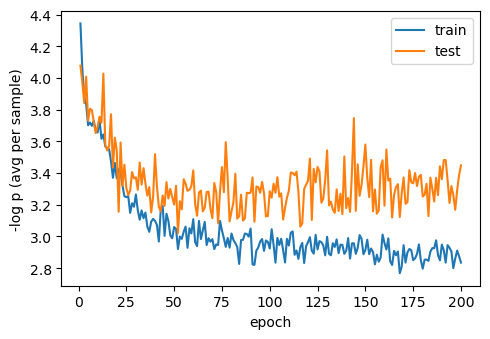

In [5]:
figures_dir = os.path.join(DOC_FOLDER, "figures", f"training_{ID_TRAINING}")
train_hist = np.load(os.path.join(figures_dir, f"train_history_{ID_TRAINING}.npy"))
test_hist = np.load(os.path.join(figures_dir, f"test_history_{ID_TRAINING}.npy"))

plt.figure(figsize=(5, 3.5))
plt.plot(np.arange(1, len(train_hist) + 1), train_hist, label="train")
plt.plot(np.arange(1, len(test_hist) + 1), test_hist, label="test")
plt.xlabel("epoch"); plt.ylabel("-log p (avg per sample)"); plt.legend(); plt.tight_layout()
plt.show()

## Direction 2: predict MO_Omega given all parameters

For every held-out test point, feed its true (standardized) parameters as
known, draw 200 samples of the omega slot, and compare the sample mean
against the true value — a standard predicted-vs-true calibration check.

MAE(predicted mean, true) = 0.00870   (omega ranges 0.0001..0.1357)


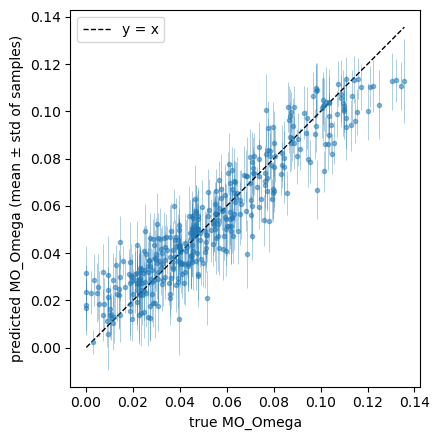

In [6]:
v_test = np.concatenate([parameters_standardized[test_idx], mo_omega_standardized[test_idx]], axis=-1)
v_known = torch.tensor(v_test, dtype=torch.float32)

mask_omega_unknown = torch.zeros(len(test_idx), total_dim)
mask_omega_unknown[:, param_dim:] = 1.0

with torch.no_grad():
    samples = model.sample(v_known, mask_omega_unknown, num_samples=200)

omega_samples_std = samples[:, :, param_dim].numpy()
omega_pred_mean = omega_samples_std.mean(axis=1) * mo_omega_std + mo_omega_mean
omega_pred_std = omega_samples_std.std(axis=1) * mo_omega_std
omega_true = mo_omega[test_idx].flatten()

mae = np.mean(np.abs(omega_pred_mean - omega_true))
print(f"MAE(predicted mean, true) = {mae:.5f}   (omega ranges {omega_true.min():.4f}..{omega_true.max():.4f})")

plt.figure(figsize=(4.5, 4.5))
plt.errorbar(omega_true, omega_pred_mean, yerr=omega_pred_std, fmt='o', ms=3, alpha=0.5, elinewidth=0.5)
lims = [omega_true.min(), omega_true.max()]
plt.plot(lims, lims, 'k--', lw=1, label="y = x")
plt.xlabel("true MO_Omega"); plt.ylabel("predicted MO_Omega (mean ± std of samples)")
plt.legend(); plt.tight_layout(); plt.show()

## Direction 1: predict all parameters given MO_Omega

Picks two example omega values from the test set (roughly the 25th and 75th
percentile), and for each draws 500 joint parameter samples. Plotting
(IN_M1, IN_M2) shows whether the model has learned the *joint* structure
between them — not just independent marginals — conditioned on omega.

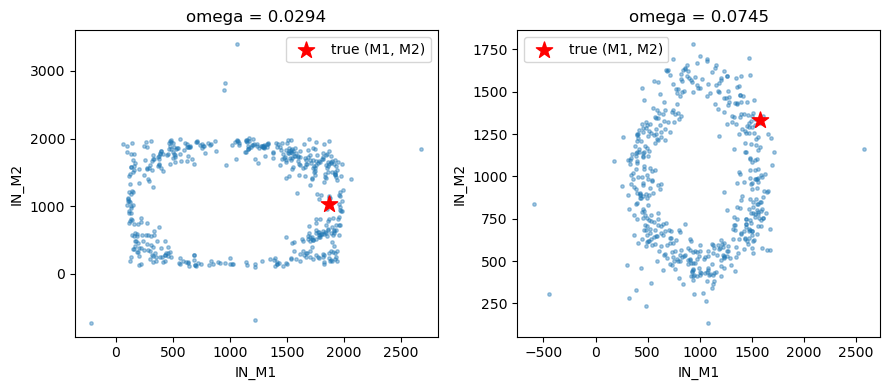

In [7]:
order = np.argsort(omega_true)
lo_idx = test_idx[order[len(order) // 4]]
hi_idx = test_idx[order[3 * len(order) // 4]]

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, idx in zip(axes, [lo_idx, hi_idx]):
    omega_val_std = float(mo_omega_standardized[idx, 0])
    v_known_row = torch.zeros(1, total_dim)
    v_known_row[0, param_dim] = omega_val_std

    mask_params_unknown = torch.zeros(1, total_dim)
    mask_params_unknown[0, :param_dim] = 1.0

    with torch.no_grad():
        samp = model.sample(v_known_row, mask_params_unknown, num_samples=500)[0]

    m1_idx, m2_idx = param_names.index("IN_M1"), param_names.index("IN_M2")
    m1_pred = samp[:, m1_idx].numpy() * parameters_std[m1_idx] + parameters_mean[m1_idx]
    m2_pred = samp[:, m2_idx].numpy() * parameters_std[m2_idx] + parameters_mean[m2_idx]

    ax.scatter(m1_pred, m2_pred, s=6, alpha=0.4)
    ax.scatter([parameters[idx, m1_idx]], [parameters[idx, m2_idx]], color='red', marker='*', s=150, label="true (M1, M2)")
    ax.set_title(f"omega = {mo_omega[idx, 0]:.4f}")
    ax.set_xlabel("IN_M1"); ax.set_ylabel("IN_M2"); ax.legend()
plt.tight_layout(); plt.show()

## Bonus: an arbitrary (non-canonical) mask

The model isn't limited to the two canonical directions above — any subset
of the joint vector can be "known." Here: given MO_Omega **and** every
parameter except IN_M2, predict IN_M2 alone. Since the synthetic omega is a
bump function of (IN_M1, IN_M2), fixing IN_M1 and omega generically leaves
two possible IN_M2 values — worth checking whether the predicted
distribution reflects that instead of collapsing to a single mode.

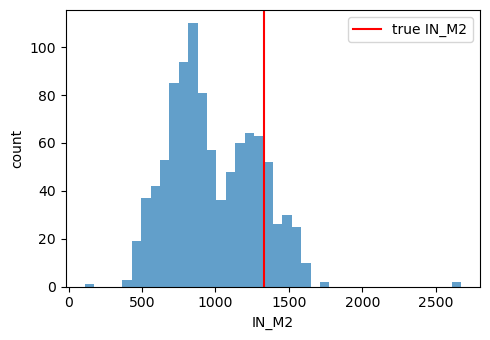

In [8]:
idx = hi_idx
row_pos = np.where(test_idx == idx)[0][0]
v_known_row = torch.tensor(v_test[row_pos : row_pos + 1], dtype=torch.float32)

m2_idx = param_names.index("IN_M2")
mask_partial = torch.zeros(1, total_dim)
mask_partial[0, m2_idx] = 1.0  # only IN_M2 unknown; omega + all other params known

with torch.no_grad():
    samp = model.sample(v_known_row, mask_partial, num_samples=1000)[0]
m2_pred = samp[:, m2_idx].numpy() * parameters_std[m2_idx] + parameters_mean[m2_idx]

plt.figure(figsize=(5, 3.5))
plt.hist(m2_pred, bins=40, alpha=0.7)
plt.axvline(parameters[idx, m2_idx], color='red', label="true IN_M2")
plt.xlabel("IN_M2"); plt.ylabel("count"); plt.legend(); plt.tight_layout(); plt.show()

## Notes

- This run used the small synthetic dataset (`example_data/`, ~1900 events
  after filtering) and a small model (`hidden_dim=64`, `num_flow_steps=4`,
  200 epochs) — enough to sanity-check the pipeline, not a real physics
  result. Point `data_folder`/hyperparams at the real dataset for that.
- The train/test loss gap that opens up after ~epoch 50 is mild overfitting,
  expected from ~1500 training rows on a model with a few thousand
  parameters — larger real datasets should mitigate it.
- Recall the depth/mixing caveat from the architecture discussion: with only
  `num_flow_steps=4` and the fixed even/odd parity split (no permutation
  between layers, since that would desync the mask — see `masking.py`),
  correlations among *many simultaneously-unknown* dims may be under-fit
  compared to the two-dim (IN_M1, IN_M2) case shown here. Worth watching if
  you condition on smaller known-sets on the real dataset.